# Comparing the versions

Robert Miller

Each version has its own folder and notebook. This one just runs them side by side on the same data, with the same fees and federal taxes, against buy and hold.

This notebook makes Table 3 in the README, along with the 2005 comparison right under it. It loads each version's `strategy.py` from its folder and reads everything it needs from `data/`, so run `python get_data.py` first, and then run every cell from top to bottom. The last cell prints the package versions and data files it was run with.

| | Folder | Holds | Signals |
|---|---|---|---|
| v1 | `v1_trend_vol` | SPY, T-bills | 12-month trend + vol targeting, max 100% SPY |
| v2 | `v2_conditional_beta` | SPY, SSO, sector ETFs, T-bills | 8/10/12-month trend, more beta in uptrends |
| v3 | `v3_leveraged_beta` | SPY, SSO, UPRO, T-bills | 200-day / 10-month trend, fixed or Kelly leverage up to 3x |

There are two tests. The first is a fixed split, where the settings are picked on 2000-2009 (v1 used 1995-2009) and tested on 2010 to now. The second is a walk-forward for v2 and v3, where every January the settings get re-picked using all the years before it and traded for 12 months. Both are compared from 2005, since v2 can't start earlier (the sector ETFs only go back to December 1998). v3 is also shown from 2000 so it has to get through the dot com crash.

Everything is after tax, assuming you sell on the last day and pay the final bill. Trades go in at the next day's close, the wash sale rule is applied, and drawdowns are from before-tax daily returns.

In [1]:
import os
import importlib.util
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.width", 200)


# same color for the same line in every chart
colors = {
    "Version 1 (trend + vol, SPY only)": "tab:purple",
    "Version 2 (conditional beta)": "tab:blue",
    "Version 2 walk-forward": "tab:blue",
    "Version 3 (leveraged beta)": "tab:green",
    "Version 3 walk-forward": "tab:green",
    "Buy and hold SPY": "tab:orange",
    "Buy and hold SSO": "tab:red",
    "Buy and hold UPRO": "tab:brown",
}


def load_version(folder):
    # every version has a strategy.py so they need different module names
    path = os.path.join(folder, "strategy.py")
    spec = importlib.util.spec_from_file_location(folder + "_strategy", path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module


v1 = load_version("v1_trend_vol")
v2 = load_version("v2_conditional_beta")
v3 = load_version("v3_leveraged_beta")

v1_data = v1.load_data()
v2_data = v2.load_data()
v3_data = v3.load_data()

print("Data through:", v2_data["dates"][-1].date())
print("Version 1 settings:", v1.chosen_settings)
print("Version 2 settings:", v2.chosen_settings)
print("Version 3 settings:", v3.chosen_settings)

Data through: 2026-10-29
Version 1 settings: {'sma_months': 12, 'vol_window': 21, 'target_vol': 0.2, 'off_weight': 0.0}
Version 2 settings: {'sma_months': 10, 'up_mode': 'leverage', 'up_size': 2.0, 'down_mode': 'cash', 'beta_window': 252, 'target_vol': 0.2}
Version 3 settings: {'trend': 'sma200', 'sizing': 'fixed', 'size': 3.0, 'vol_source': 'realized', 'check': 'monthly'}


## Fixed split (2010 to now)

This is the first column of Table 3 in the README.

In [2]:
test_start = "2010-01-01"


def v1_run(taxes):
    s = v1.chosen_settings
    return v1.run_backtest(v1_data, s["sma_months"], s["vol_window"], s["target_vol"], s["off_weight"],
                           start=test_start, taxes=taxes)


runs = {
    "Version 1 (trend + vol, SPY only)": v1_run,
    "Version 2 (conditional beta)": lambda taxes: v2.run_strategy(v2_data, v2.chosen_settings, start=test_start, taxes=taxes),
    "Version 3 (leveraged beta)": lambda taxes: v3.run_strategy(v3_data, v3.chosen_settings, start=test_start, taxes=taxes),
    "Buy and hold SPY": lambda taxes: v2.run_fixed(v2_data, {"SPY": 1.0}, start=test_start, taxes=taxes),
    "Buy and hold SSO": lambda taxes: v2.run_fixed(v2_data, {"SSO": 1.0}, start=test_start, taxes=taxes),
    "Buy and hold UPRO": lambda taxes: v3.run_fixed(v3_data, {"UPRO": 1.0}, start=test_start, taxes=taxes),
}

pre_tax = {name: run(False) for name, run in runs.items()}
with_tax = {name: run(True) for name, run in runs.items()}


def summarize(bt, taxed):
    years = len(taxed) / 252
    stats = v2.get_stats(bt["strategy_return"], bt["tbill_return"], bt["spy_return"])
    return {
        "value_before_tax": bt["value"].iloc[-1],
        "value_after_tax_sold": taxed.attrs["liquidation_value"],
        "cagr_after_tax": (taxed.attrs["liquidation_value"] / 10000) ** (1 / years) - 1,
        "sharpe": stats["sharpe"],
        "max_drawdown": stats["max_drawdown"],
        "beta": stats["beta"],
    }


fixed_table = pd.DataFrame({name: summarize(pre_tax[name], with_tax[name]) for name in runs}).T
fixed_table["beats_spy_after_tax"] = fixed_table["value_after_tax_sold"] > fixed_table.loc["Buy and hold SPY", "value_after_tax_sold"]
fixed_table

,value_before_tax,value_after_tax_sold,cagr_after_tax,sharpe,max_drawdown,beta,beats_spy_after_tax
"Version 1 (trend + vol, SPY only)","44,987.771","36,603.609",0.080,0.651,-0.209,0.571,False
Version 2 (conditional beta),"64,159.596","48,695.916",0.099,0.506,-0.448,1.135,False
Version 3 (leveraged beta),"139,481.160","96,681.207",0.145,0.567,-0.642,1.663,True
Buy and hold SPY,"91,144.331","76,769.447",0.129,0.772,-0.337,0.999,False
Buy and hold SSO,"311,165.088","261,801.029",0.215,0.730,-0.593,1.997,True
Buy and hold UPRO,"725,134.483","611,415.255",0.278,0.730,-0.768,2.989,True


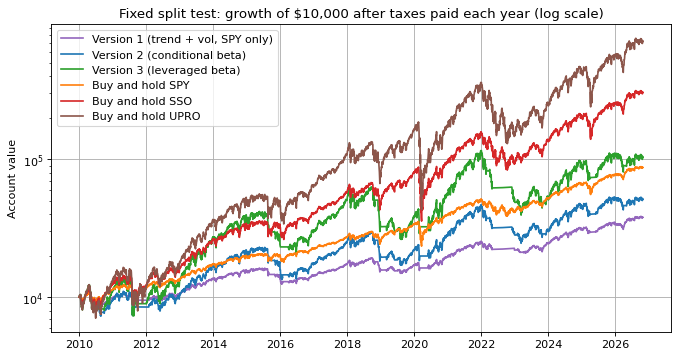

In [3]:
plt.figure(figsize=(10,5))
for name in runs:
    plt.plot(with_tax[name].index, with_tax[name]["value"], label=name, color=colors[name])
plt.yscale("log")
plt.title("Fixed split test: growth of $10,000 after taxes paid each year (log scale)")
plt.ylabel("Account value")
plt.legend()
plt.grid(True)
plt.show()

## Walk-forward (2005 to now)

These are the 2005 numbers under Table 3 in the README.

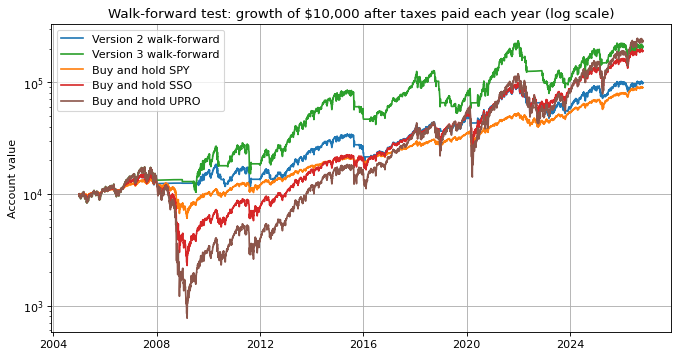

,value_before_tax,value_after_tax_sold,cagr_after_tax,sharpe,max_drawdown,beta,beats_spy_after_tax
Version 2 walk-forward,"136,102.392","93,493.980",0.108,0.543,-0.484,0.853,True
Version 3 walk-forward,"315,113.133","194,600.278",0.146,0.568,-0.642,1.288,True
Buy and hold SPY,"94,966.294","78,879.141",0.099,0.549,-0.552,1.000,False
Buy and hold SSO,"200,264.851","164,634.462",0.137,0.510,-0.847,1.960,True
Buy and hold UPRO,"237,460.160","201,225.599",0.148,0.512,-0.956,2.993,True


In [4]:
wf_start = "2005-01-01"

v2_weights, v2_picks = v2.walk_forward(v2_data, v2.get_settings_grid())
v3_weights, v3_picks = v3.walk_forward(v3_data, v3.get_settings_grid())

walk_runs = {
    "Version 2 walk-forward": (v2.simulate(v2_data, v2_weights, start=wf_start),
                               v2.simulate(v2_data, v2_weights, start=wf_start, taxes=True)),
    "Version 3 walk-forward": (v3.simulate(v3_data, v3_weights, start=wf_start),
                               v3.simulate(v3_data, v3_weights, start=wf_start, taxes=True)),
    "Buy and hold SPY": (v2.run_fixed(v2_data, {"SPY": 1.0}, start=wf_start),
                         v2.run_fixed(v2_data, {"SPY": 1.0}, start=wf_start, taxes=True)),
    "Buy and hold SSO": (v2.run_fixed(v2_data, {"SSO": 1.0}, start=wf_start),
                         v2.run_fixed(v2_data, {"SSO": 1.0}, start=wf_start, taxes=True)),
    "Buy and hold UPRO": (v3.run_fixed(v3_data, {"UPRO": 1.0}, start=wf_start),
                          v3.run_fixed(v3_data, {"UPRO": 1.0}, start=wf_start, taxes=True)),
}

walk_table = pd.DataFrame({name: summarize(bt, taxed) for name, (bt, taxed) in walk_runs.items()}).T
walk_table["beats_spy_after_tax"] = walk_table["value_after_tax_sold"] > walk_table.loc["Buy and hold SPY", "value_after_tax_sold"]

plt.figure(figsize=(10,5))
for name, (bt, taxed) in walk_runs.items():
    plt.plot(taxed.index, taxed["value"], label=name, color=colors[name])
plt.yscale("log")
plt.title("Walk-forward test: growth of $10,000 after taxes paid each year (log scale)")
plt.ylabel("Account value")
plt.legend()
plt.grid(True)
plt.show()

walk_table

In [5]:
# how much tax + trading costs took off
rows = {}
for name, (bt, taxed) in walk_runs.items():
    years = len(bt) / 252
    rows[name] = {
        "cagr_before_tax": (bt["value"].iloc[-1] / 10000) ** (1 / years) - 1,
        "cagr_after_tax": (taxed.attrs["liquidation_value"] / 10000) ** (1 / years) - 1,
        "turnover_per_year": (bt["traded"] / bt["value"]).sum() / years,
        "trading_costs": bt["cost"].sum(),
    }
drag = pd.DataFrame(rows).T
drag["tax_and_cost_drag"] = drag["cagr_before_tax"] - drag["cagr_after_tax"]
drag

,cagr_before_tax,cagr_after_tax,turnover_per_year,trading_costs,tax_and_cost_drag
Version 2 walk-forward,0.127,0.108,2.091,"1,207.236",0.019
Version 3 walk-forward,0.172,0.146,1.423,"1,771.229",0.026
Buy and hold SPY,0.109,0.099,0.046,4.998,0.009
Buy and hold SSO,0.147,0.137,0.046,4.998,0.010
Buy and hold UPRO,0.156,0.148,0.046,4.998,0.009


## v3 from 2000

This is the walk-forward column of Table 3 in the README, along with the drawdowns.

In [6]:
start_2000 = "2000-01-01"
runs_2000 = {
    "Version 3 walk-forward": (v3.simulate(v3_data, v3_weights, start=start_2000),
                               v3.simulate(v3_data, v3_weights, start=start_2000, taxes=True)),
    "Buy and hold SPY": (v3.run_fixed(v3_data, {"SPY": 1.0}, start=start_2000),
                         v3.run_fixed(v3_data, {"SPY": 1.0}, start=start_2000, taxes=True)),
    "Buy and hold SSO": (v3.run_fixed(v3_data, {"SSO": 1.0}, start=start_2000),
                         v3.run_fixed(v3_data, {"SSO": 1.0}, start=start_2000, taxes=True)),
    "Buy and hold UPRO": (v3.run_fixed(v3_data, {"UPRO": 1.0}, start=start_2000),
                          v3.run_fixed(v3_data, {"UPRO": 1.0}, start=start_2000, taxes=True)),
}
table_2000 = pd.DataFrame({name: summarize(bt, taxed) for name, (bt, taxed) in runs_2000.items()}).T
table_2000["beats_spy_after_tax"] = table_2000["value_after_tax_sold"] > table_2000.loc["Buy and hold SPY", "value_after_tax_sold"]
table_2000

,value_before_tax,value_after_tax_sold,cagr_after_tax,sharpe,max_drawdown,beta,beats_spy_after_tax
Version 3 walk-forward,"182,474.055","121,386.602",0.098,0.426,-0.822,1.408,True
Buy and hold SPY,"84,589.238","69,792.962",0.075,0.412,-0.552,1.000,False
Buy and hold SSO,"104,153.797","86,467.499",0.084,0.371,-0.888,1.969,True
Buy and hold UPRO,"61,352.836","53,118.347",0.064,0.375,-0.982,2.994,False


## Summary

(Data through October 29, 2026.)

From 2010 on, with settings picked on earlier years, nothing beat buy and hold SSO or UPRO, and only v3 beat SPY (14.5% vs 12.9% a year after tax, with a -64% max drawdown vs -34%).

From 2000 on, v3's walk-forward beat everything after taxes: $121,400 vs $86,500 for SSO, $69,800 for SPY and $53,100 for UPRO (9.8% vs 8.4%, 7.5% and 6.4% a year). However, it fell 82% along the way, because the walk-forward picked plain 3x buy and hold for 2000 and 2001, right into the dot com crash. From 2005, v3 roughly tied buy and hold UPRO (14.6% vs 14.8%) and beat SSO (13.7%) and SPY (9.9%), and v2 beat SPY (10.8%) but not SSO.

None of it is statistically strong though. v3's average yearly lead was about t = 1.7 against SPY and t = 0.9 against SSO, and since UPRO actually started trading in June 2009, v3 has trailed SSO and UPRO before tax. In addition, outside the US the same rule beat holding the DAX or Nikkei with 2x from 1994 or 2000, but lost badly from 2010 on, and on the Nikkei from 1994 it did worse than just holding the index. v1 is the lowest risk (beta 0.57, max drawdown -21% from 2010), but it gave up the most return.

Overall, the trend-filtered leverage rule makes its money by getting out of long bear markets like 2000-2002 and 2008. In long bull markets it trails leveraged buy and hold, and the drawdowns are huge either way. I don't think the backtest shows a reliable way to beat buy and hold SSO.

## Environment

This prints the package versions I last ran this notebook with, plus the data files it read. Yahoo goes back and changes old prices once in a while, so if your hashes don't match mine, your download is actually a little different from the one I used.

In [ ]:
import sys
import hashlib
import matplotlib
import yfinance

print("Python", sys.version.split()[0])
for module in [pd, np, matplotlib, yfinance]:
    print(module.__name__, module.__version__)
print()

for name in ["SPY", "SSO", "UPRO", "VIX", "XLB", "XLE", "XLF", "XLI", "XLK", "XLP", "XLU", "XLV", "XLY", "dtb3"]:
    path = "data/" + name + ".csv"
    with open(path, "rb") as f:
        sha = hashlib.sha256(f.read()).hexdigest()[:12]
    last_row = pd.read_csv(path).iloc[-1, 0]
    print(name.ljust(6), "last row", last_row, " sha256", sha)